In [1]:
# ============================================================================
# MSGR-RAG Component 4: Knowledge Graph Construction
# ============================================================================
# Purpose: Build NetworkX multi-scale knowledge graphs (G_E, G_C, G_D)
# Author: Pavan Kumar Reddy Yannam
# Date: December 2024
# ============================================================================

In [2]:
# # Component 4: Knowledge Graph Construction
# 
# **Objectives:**
# 1. Build NetworkX graphs for entity, concept, and domain levels
# 2. Implement graph querying functions
# 3. Create graph visualization utilities
# 4. Store abstraction mappings in graph metadata
# 5. Validate graph structure and connectivity
# 6. Export graphs for verification framework

In [3]:
# ## Section 1: Environment Setup

In [5]:
import pandas as pd
import numpy as np
import json
import networkx as nx
import matplotlib.pyplot as plt
from pathlib import Path
from collections import Counter
import warnings
import pickle

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 150)

print("✓ Libraries imported successfully")
print(f"NetworkX version: {nx.__version__}")

# %%
# Define paths
DATA_DIR = Path("../Datasets")
INTERMEDIATE_DIR = DATA_DIR / "intermediate"

# Input files from previous components
ENTITY_CATALOG_PATH = INTERMEDIATE_DIR / "entity_catalog.csv"
ENTITY_RELATIONSHIPS_PATH = INTERMEDIATE_DIR / "entity_relationships.csv"
CONCEPT_MAPPINGS_PATH = INTERMEDIATE_DIR / "concept_mappings.csv"
DOMAIN_MAPPINGS_PATH = INTERMEDIATE_DIR / "domain_mappings.csv"
CONCEPT_RELATIONSHIPS_PATH = INTERMEDIATE_DIR / "concept_relationships.csv"
DOMAIN_RELATIONSHIPS_PATH = INTERMEDIATE_DIR / "domain_relationships.csv"

# Output paths for this component
GRAPH_ENTITY_PATH = INTERMEDIATE_DIR / "graph_entity.gpickle"
GRAPH_CONCEPT_PATH = INTERMEDIATE_DIR / "graph_concept.gpickle"
GRAPH_DOMAIN_PATH = INTERMEDIATE_DIR / "graph_domain.gpickle"
GRAPH_STATISTICS_PATH = INTERMEDIATE_DIR / "graph_statistics.json"
GRAPH_VIZ_PATH = INTERMEDIATE_DIR / "graph_visualizations.png"

print(f"✓ Input files configured")
print(f"✓ Output files configured")


✓ Libraries imported successfully
NetworkX version: 3.6.1
✓ Input files configured
✓ Output files configured


In [6]:
# ## Section 2: Load Data

In [7]:
print("Loading data from previous components...")
print("=" * 80)

# Entity level
entity_catalog_df = pd.read_csv(ENTITY_CATALOG_PATH)
entity_relationships_df = pd.read_csv(ENTITY_RELATIONSHIPS_PATH)

print(f"✓ Entity catalog: {len(entity_catalog_df)} entities")
print(f"✓ Entity relationships: {len(entity_relationships_df):,} edges")

# Concept level
concept_mappings_df = pd.read_csv(CONCEPT_MAPPINGS_PATH)
concept_relationships_df = pd.read_csv(CONCEPT_RELATIONSHIPS_PATH)

print(f"✓ Concept mappings: {len(concept_mappings_df)} mappings")
print(f"✓ Concept relationships: {len(concept_relationships_df):,} edges")

# Domain level
domain_mappings_df = pd.read_csv(DOMAIN_MAPPINGS_PATH)
domain_relationships_df = pd.read_csv(DOMAIN_RELATIONSHIPS_PATH)

print(f"✓ Domain mappings: {len(domain_mappings_df)} mappings")
print(f"✓ Domain relationships: {len(domain_relationships_df):,} edges")

Loading data from previous components...
✓ Entity catalog: 149 entities
✓ Entity relationships: 103,552 edges
✓ Concept mappings: 149 mappings
✓ Concept relationships: 348 edges
✓ Domain mappings: 39 mappings
✓ Domain relationships: 119 edges


In [8]:
# ## Section 3: Build Entity-Level Graph (G_E)

In [9]:
print("Building Entity-Level Graph (G_E):")
print("=" * 80)

# Create directed graph
G_E = nx.DiGraph()

print("\n1. Adding nodes...")

# Add all entities as nodes with attributes
for idx, row in entity_catalog_df.iterrows():
    G_E.add_node(
        row['entity_name'],
        entity_id=row['entity_id'],
        entity_type=row['entity_type'],
        source=row['source'],
        graph_level='entity'
    )

print(f"✓ Added {G_E.number_of_nodes()} nodes")

# Add concept mapping to node attributes
print("\n2. Adding concept mappings to node metadata...")
entity_to_concept_map = dict(zip(
    concept_mappings_df['entity_name'],
    concept_mappings_df['concept_name']
))

for node in G_E.nodes():
    if node in entity_to_concept_map:
        G_E.nodes[node]['concept'] = entity_to_concept_map[node]

print(f"✓ Added concept mappings to nodes")

# Add edges (relationships)
print("\n3. Adding edges...")

for idx, row in entity_relationships_df.iterrows():
    G_E.add_edge(
        row['subject'],
        row['object'],
        predicate=row['predicate'],
        relationship_type=row['relationship_type'],
        confidence=row['confidence'],
        source=row['source']
    )
    
    # Progress indicator
    if (idx + 1) % 20000 == 0:
        print(f"  Added {idx+1:,} edges...")

print(f"✓ Added {G_E.number_of_edges():,} edges")

# Graph statistics
print("\n" + "=" * 80)
print("G_E STATISTICS")
print("=" * 80)
print(f"Nodes: {G_E.number_of_nodes()}")
print(f"Edges: {G_E.number_of_edges():,}")
print(f"Graph density: {nx.density(G_E):.6f}")
print(f"Is directed: {G_E.is_directed()}")

# Check connectivity
if G_E.number_of_nodes() > 0:
    print(f"\nConnectivity:")
    if nx.is_weakly_connected(G_E):
        print(f"  Weakly connected: Yes")
    else:
        num_components = nx.number_weakly_connected_components(G_E)
        print(f"  Weakly connected: No ({num_components} components)")
        largest_cc = max(nx.weakly_connected_components(G_E), key=len)
        print(f"  Largest component: {len(largest_cc)} nodes")

# Node degree statistics
degrees = dict(G_E.degree())
if degrees:
    degree_values = list(degrees.values())
    print(f"\nDegree statistics:")
    print(f"  Mean degree: {np.mean(degree_values):.2f}")
    print(f"  Median degree: {np.median(degree_values):.2f}")
    print(f"  Max degree: {np.max(degree_values)}")
    print(f"  Min degree: {np.min(degree_values)}")

Building Entity-Level Graph (G_E):

1. Adding nodes...
✓ Added 149 nodes

2. Adding concept mappings to node metadata...
✓ Added concept mappings to nodes

3. Adding edges...
  Added 20,000 edges...
  Added 40,000 edges...
  Added 60,000 edges...
  Added 80,000 edges...
  Added 100,000 edges...
✓ Added 103,551 edges

G_E STATISTICS
Nodes: 3920
Edges: 103,551
Graph density: 0.006741
Is directed: True

Connectivity:
  Weakly connected: Yes

Degree statistics:
  Mean degree: 52.83
  Median degree: 28.00
  Max degree: 2271
  Min degree: 1


In [10]:
# ## Section 4: Build Concept-Level Graph (G_C)

In [11]:
print("Building Concept-Level Graph (G_C):")
print("=" * 80)

# Create directed graph
G_C = nx.DiGraph()

print("\n1. Adding nodes...")

# Get unique concepts from concept_mappings
unique_concepts = concept_mappings_df[['concept_name', 'concept_type']].drop_duplicates()

for idx, row in unique_concepts.iterrows():
    G_C.add_node(
        row['concept_name'],
        concept_type=row['concept_type'],
        graph_level='concept'
    )

print(f"✓ Added {G_C.number_of_nodes()} nodes")

# Add domain mapping to node attributes
print("\n2. Adding domain mappings to node metadata...")
concept_to_domain_map = dict(zip(
    domain_mappings_df['concept_name'],
    domain_mappings_df['domain_name']
))

for node in G_C.nodes():
    if node in concept_to_domain_map:
        G_C.nodes[node]['domain'] = concept_to_domain_map[node]

print(f"✓ Added domain mappings to nodes")

# Add entity-level members to concept nodes
print("\n3. Adding entity members to concept nodes...")
concept_to_entities = concept_mappings_df.groupby('concept_name')['entity_name'].apply(list).to_dict()

for node in G_C.nodes():
    if node in concept_to_entities:
        G_C.nodes[node]['entity_members'] = concept_to_entities[node]
        G_C.nodes[node]['num_entities'] = len(concept_to_entities[node])

print(f"✓ Added entity membership information")

# Add edges
print("\n4. Adding edges...")

for idx, row in concept_relationships_df.iterrows():
    # Only add edge if both nodes exist
    if row['subject_concept'] in G_C.nodes() and row['object_concept'] in G_C.nodes():
        G_C.add_edge(
            row['subject_concept'],
            row['object_concept'],
            predicate=row['predicate'],
            relationship_type=row['relationship_type'],
            source=row['source']
        )

print(f"✓ Added {G_C.number_of_edges():,} edges")

# Graph statistics
print("\n" + "=" * 80)
print("G_C STATISTICS")
print("=" * 80)
print(f"Nodes: {G_C.number_of_nodes()}")
print(f"Edges: {G_C.number_of_edges():,}")
print(f"Graph density: {nx.density(G_C):.6f}")
print(f"Is directed: {G_C.is_directed()}")

# Check connectivity
if G_C.number_of_nodes() > 0:
    print(f"\nConnectivity:")
    if nx.is_weakly_connected(G_C):
        print(f"  Weakly connected: Yes")
    else:
        num_components = nx.number_weakly_connected_components(G_C)
        print(f"  Weakly connected: No ({num_components} components)")
        largest_cc = max(nx.weakly_connected_components(G_C), key=len)
        print(f"  Largest component: {len(largest_cc)} nodes")

# Node degree statistics
degrees = dict(G_C.degree())
if degrees:
    degree_values = list(degrees.values())
    print(f"\nDegree statistics:")
    print(f"  Mean degree: {np.mean(degree_values):.2f}")
    print(f"  Median degree: {np.median(degree_values):.2f}")
    print(f"  Max degree: {np.max(degree_values)}")
    print(f"  Min degree: {np.min(degree_values)}")

# Concept size distribution
concept_sizes = [G_C.nodes[n].get('num_entities', 0) for n in G_C.nodes()]
if concept_sizes:
    print(f"\nConcept size statistics (entities per concept):")
    print(f"  Mean: {np.mean(concept_sizes):.2f}")
    print(f"  Median: {np.median(concept_sizes):.2f}")
    print(f"  Max: {np.max(concept_sizes)}")
    print(f"  Min: {np.min(concept_sizes)}")

Building Concept-Level Graph (G_C):

1. Adding nodes...
✓ Added 39 nodes

2. Adding domain mappings to node metadata...
✓ Added domain mappings to nodes

3. Adding entity members to concept nodes...
✓ Added entity membership information

4. Adding edges...
✓ Added 339 edges

G_C STATISTICS
Nodes: 39
Edges: 339
Graph density: 0.228745
Is directed: True

Connectivity:
  Weakly connected: Yes

Degree statistics:
  Mean degree: 17.38
  Median degree: 13.00
  Max degree: 59
  Min degree: 2

Concept size statistics (entities per concept):
  Mean: 3.82
  Median: 2.00
  Max: 53
  Min: 1


In [12]:
# ## Section 5: Build Domain-Level Graph (G_D)

In [24]:
print("Building Domain-Level Graph (G_D):")
print("=" * 80)

# Create MULTI-directed graph — allows multiple predicates between the same
# domain pair instead of silently overwriting (this was the source of the
# 39 lost edges: 119 CSV rows -> only 80 unique (subj,obj) pairs under DiGraph)
G_D = nx.MultiDiGraph()

print("\n1. Adding nodes...")

# Get unique domains
unique_domains = domain_mappings_df['domain_name'].unique()

for domain in unique_domains:
    G_D.add_node(
        domain,
        graph_level='domain'
    )

print(f"✓ Added {G_D.number_of_nodes()} nodes")

# Add concept-level members to domain nodes
print("\n2. Adding concept members to domain nodes...")
domain_to_concepts = domain_mappings_df.groupby('domain_name')['concept_name'].apply(list).to_dict()

for node in G_D.nodes():
    if node in domain_to_concepts:
        G_D.nodes[node]['concept_members'] = domain_to_concepts[node]
        G_D.nodes[node]['num_concepts'] = len(domain_to_concepts[node])

print(f"✓ Added concept membership information")

# Add edges
print("\n3. Adding edges...")

for idx, row in domain_relationships_df.iterrows():
    # Only add edge if both nodes exist
    if row['subject_domain'] in G_D.nodes() and row['object_domain'] in G_D.nodes():
        G_D.add_edge(
            row['subject_domain'],
            row['object_domain'],
            predicate=row['predicate'],
            source=row['source']
        )

print(f"✓ Added {G_D.number_of_edges():,} edges")

# Sanity check: confirm no silent overwrites happened
expected_edges = len(domain_relationships_df)
actual_edges = G_D.number_of_edges()
if expected_edges != actual_edges:
    print(f"⚠ WARNING: CSV had {expected_edges} rows but graph has {actual_edges} edges — "
          f"check for exact duplicate rows in domain_relationships_df")
else:
    print(f"✓ Verified: all {expected_edges} CSV rows preserved as distinct edges")

# Graph statistics
print("\n" + "=" * 80)
print("G_D STATISTICS")
print("=" * 80)
print(f"Nodes: {G_D.number_of_nodes()}")
print(f"Edges: {G_D.number_of_edges():,}")
print(f"Graph density: {nx.density(G_D):.6f}")
print(f"Is directed: {G_D.is_directed()}")
print(f"Is multigraph: {G_D.is_multigraph()}")

# Check connectivity
if G_D.number_of_nodes() > 0:
    print(f"\nConnectivity:")
    if nx.is_weakly_connected(G_D):
        print(f"  Weakly connected: Yes")
    else:
        num_components = nx.number_weakly_connected_components(G_D)
        print(f"  Weakly connected: No ({num_components} components)")
        largest_cc = max(nx.weakly_connected_components(G_D), key=len)
        print(f"  Largest component: {len(largest_cc)} nodes")
        isolated = [n for n in G_D.nodes() if G_D.degree(n) == 0]
        if isolated:
            print(f"  Isolated nodes (degree 0): {isolated}")

# Node degree statistics
degrees = dict(G_D.degree())
if degrees:
    degree_values = list(degrees.values())
    print(f"\nDegree statistics:")
    print(f"  Mean degree: {np.mean(degree_values):.2f}")
    print(f"  Median degree: {np.median(degree_values):.2f}")
    print(f"  Max degree: {np.max(degree_values)}")
    print(f"  Min degree: {np.min(degree_values)}")

# Domain size distribution
domain_sizes = [G_D.nodes[n].get('num_concepts', 0) for n in G_D.nodes()]
if domain_sizes:
    print(f"\nDomain size statistics (concepts per domain):")
    print(f"  Mean: {np.mean(domain_sizes):.2f}")
    print(f"  Median: {np.median(domain_sizes):.2f}")
    print(f"  Max: {np.max(domain_sizes)}")
    print(f"  Min: {np.min(domain_sizes)}")

Building Domain-Level Graph (G_D):

1. Adding nodes...
✓ Added 16 nodes

2. Adding concept members to domain nodes...
✓ Added concept membership information

3. Adding edges...
✓ Added 119 edges
✓ Verified: all 119 CSV rows preserved as distinct edges

G_D STATISTICS
Nodes: 16
Edges: 119
Graph density: 0.495833
Is directed: True
Is multigraph: True

Connectivity:
  Weakly connected: No (2 components)
  Largest component: 15 nodes
  Isolated nodes (degree 0): ['General_Medicine']

Degree statistics:
  Mean degree: 14.88
  Median degree: 9.00
  Max degree: 39
  Min degree: 0

Domain size statistics (concepts per domain):
  Mean: 2.44
  Median: 2.00
  Max: 6
  Min: 1


In [25]:
# ## Section 6: Graph Querying Functions

In [26]:
print("Implementing Graph Query Functions:")
print("=" * 80)

# ============================================================================
# Query Function 1: Get neighbors
# ============================================================================

def get_neighbors(graph, node, predicate=None):
    """
    Get neighbors of a node, optionally filtered by predicate
    
    Args:
        graph: NetworkX graph
        node: Node name
        predicate: Optional predicate filter
    
    Returns:
        List of (neighbor, edge_data) tuples
    """
    if node not in graph:
        return []
    
    neighbors = []
    for neighbor in graph.neighbors(node):
        edge_data = graph[node][neighbor]
        
        if predicate is None or edge_data.get('predicate') == predicate:
            neighbors.append((neighbor, edge_data))
    
    return neighbors

# Test
print("\n1. get_neighbors() function")
sample_drug = list(G_E.nodes())[0]
neighbors = get_neighbors(G_E, sample_drug, predicate='interacts_with')
print(f"   Sample: {sample_drug} has {len(neighbors)} 'interacts_with' neighbors")

# ============================================================================
# Query Function 2: Check if relationship exists
# ============================================================================

def has_relationship(graph, subject, predicate, obj):
    """
    Check if a specific relationship exists in the graph
    
    Args:
        graph: NetworkX graph
        subject: Subject node
        predicate: Relationship type
        obj: Object node
    
    Returns:
        Boolean
    """
    if subject not in graph or obj not in graph:
        return False
    
    if graph.has_edge(subject, obj):
        edge_data = graph[subject][obj]
        return edge_data.get('predicate') == predicate
    
    return False

# Test
print("\n2. has_relationship() function")
if len(entity_relationships_df) > 0:
    sample_rel = entity_relationships_df.iloc[0]
    exists = has_relationship(G_E, sample_rel['subject'], sample_rel['predicate'], sample_rel['object'])
    print(f"   Sample: ({sample_rel['subject']}, {sample_rel['predicate']}, {sample_rel['object']}) exists: {exists}")

# ============================================================================
# Query Function 3: Get abstraction (entity → concept → domain)
# ============================================================================

def get_abstraction_chain(entity_name, G_E, G_C, G_D):
    """
    Get the full abstraction chain for an entity
    
    Args:
        entity_name: Entity name
        G_E, G_C, G_D: The three graphs
    
    Returns:
        Dict with entity, concept, and domain
    """
    result = {
        'entity': entity_name,
        'concept': None,
        'domain': None
    }
    
    # Get concept (φ_EC)
    if entity_name in G_E.nodes():
        concept = G_E.nodes[entity_name].get('concept')
        result['concept'] = concept
        
        # Get domain (φ_CD)
        if concept and concept in G_C.nodes():
            domain = G_C.nodes[concept].get('domain')
            result['domain'] = domain
    
    return result

# Test
print("\n3. get_abstraction_chain() function")
sample_entity = list(G_E.nodes())[0]
chain = get_abstraction_chain(sample_entity, G_E, G_C, G_D)
print(f"   Sample: {sample_entity}")
print(f"     → Concept: {chain['concept']}")
print(f"     → Domain: {chain['domain']}")

# ============================================================================
# Query Function 4: Get all relationships by type
# ============================================================================

def get_relationships_by_type(graph, predicate):
    """
    Get all relationships of a specific type
    
    Args:
        graph: NetworkX graph
        predicate: Relationship type
    
    Returns:
        List of (subject, object, edge_data) tuples
    """
    relationships = []
    
    for u, v, data in graph.edges(data=True):
        if data.get('predicate') == predicate:
            relationships.append((u, v, data))
    
    return relationships

# Test
print("\n4. get_relationships_by_type() function")
treats_rels = get_relationships_by_type(G_E, 'treats')
print(f"   Found {len(treats_rels)} 'treats' relationships in G_E")

print("\n✓ Graph query functions implemented and tested")

Implementing Graph Query Functions:

1. get_neighbors() function
   Sample: COPD has 0 'interacts_with' neighbors

2. has_relationship() function
   Sample: (Lepirudin, interacts_with, Ceftezole) exists: True

3. get_abstraction_chain() function
   Sample: COPD
     → Concept: Respiratory_Disorders
     → Domain: Pulmonology

4. get_relationships_by_type() function
   Found 189 'treats' relationships in G_E

✓ Graph query functions implemented and tested


In [27]:
# ## Section 7: Graph Visualization

Creating Graph Visualizations:

1. Entity-level subgraph...
2. Concept-level graph...
3. Domain-level graph...
4. Degree distributions...

✓ Saved visualization: ../Datasets/intermediate/graph_visualizations.png


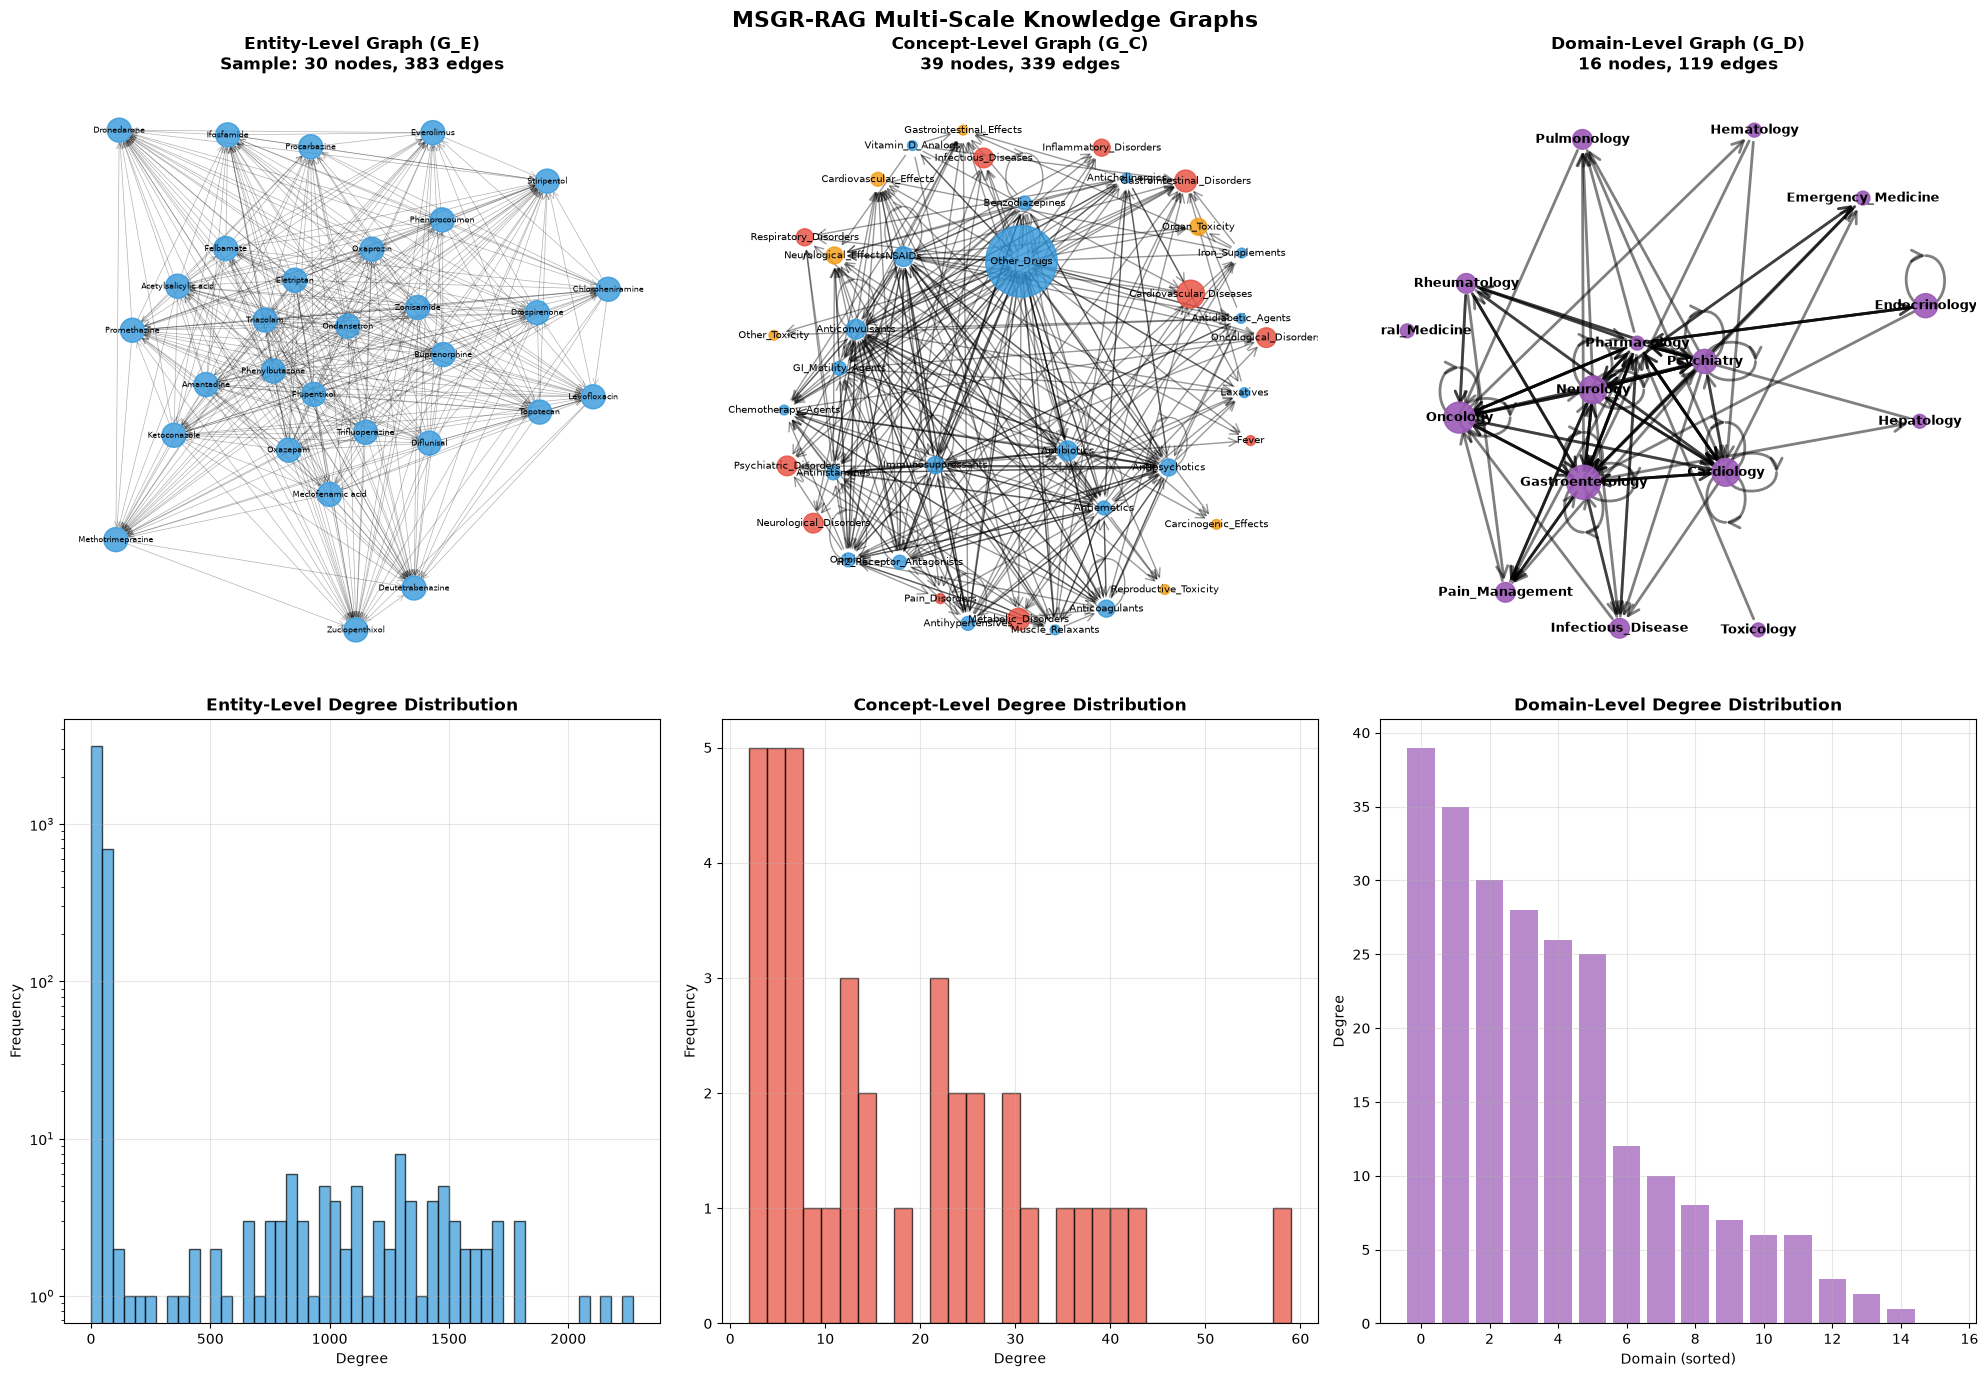

In [28]:
print("Creating Graph Visualizations:")
print("=" * 80)

# Create figure with subplots
fig, axes = plt.subplots(2, 3, figsize=(20, 14))
fig.suptitle('MSGR-RAG Multi-Scale Knowledge Graphs', fontsize=16, fontweight='bold')

# ============================================================================
# Visualization 1: Entity-level subgraph (sample)
# ============================================================================
print("\n1. Entity-level subgraph...")

ax = axes[0, 0]

# Sample a small subgraph (30 nodes max for visibility)
if G_E.number_of_nodes() > 30:
    # Get highest degree nodes
    degrees = dict(G_E.degree())
    top_nodes = sorted(degrees, key=degrees.get, reverse=True)[:30]
    G_E_sample = G_E.subgraph(top_nodes).copy()
else:
    G_E_sample = G_E

# Layout
pos = nx.spring_layout(G_E_sample, k=2, iterations=50, seed=42)

# Node colors by type
node_colors = []
for node in G_E_sample.nodes():
    entity_type = G_E_sample.nodes[node].get('entity_type', 'Unknown')
    if entity_type == 'Drug':
        node_colors.append('#3498db')  # Blue
    elif entity_type == 'Condition':
        node_colors.append('#e74c3c')  # Red
    elif entity_type == 'Adverse_Effect':
        node_colors.append('#f39c12')  # Orange
    else:
        node_colors.append('#95a5a6')  # Gray

# Draw
nx.draw_networkx_nodes(G_E_sample, pos, node_color=node_colors, node_size=300, alpha=0.8, ax=ax)
nx.draw_networkx_edges(G_E_sample, pos, alpha=0.3, width=0.5, arrows=True, 
                       arrowsize=10, arrowstyle='->', ax=ax)
nx.draw_networkx_labels(G_E_sample, pos, font_size=6, ax=ax)

ax.set_title(f'Entity-Level Graph (G_E)\nSample: {G_E_sample.number_of_nodes()} nodes, {G_E_sample.number_of_edges()} edges',
            fontsize=12, fontweight='bold')
ax.axis('off')

# ============================================================================
# Visualization 2: Concept-level graph
# ============================================================================
print("2. Concept-level graph...")

ax = axes[0, 1]

# Sample if too large
if G_C.number_of_nodes() > 40:
    degrees = dict(G_C.degree())
    top_nodes = sorted(degrees, key=degrees.get, reverse=True)[:40]
    G_C_sample = G_C.subgraph(top_nodes).copy()
else:
    G_C_sample = G_C

# Layout
pos = nx.spring_layout(G_C_sample, k=3, iterations=50, seed=42)

# Node colors by concept type
node_colors = []
for node in G_C_sample.nodes():
    concept_type = G_C_sample.nodes[node].get('concept_type', 'Unknown')
    if concept_type == 'Drug_Class':
        node_colors.append('#3498db')  # Blue
    elif concept_type == 'Disease_Category':
        node_colors.append('#e74c3c')  # Red
    elif concept_type == 'Toxicity_Category':
        node_colors.append('#f39c12')  # Orange
    else:
        node_colors.append('#95a5a6')  # Gray

# Node sizes by number of entities
node_sizes = [G_C_sample.nodes[n].get('num_entities', 1) * 50 for n in G_C_sample.nodes()]

# Draw
nx.draw_networkx_nodes(G_C_sample, pos, node_color=node_colors, node_size=node_sizes, 
                      alpha=0.8, ax=ax)
nx.draw_networkx_edges(G_C_sample, pos, alpha=0.4, width=1, arrows=True,
                       arrowsize=15, arrowstyle='->', ax=ax)
nx.draw_networkx_labels(G_C_sample, pos, font_size=7, ax=ax)

ax.set_title(f'Concept-Level Graph (G_C)\n{G_C_sample.number_of_nodes()} nodes, {G_C_sample.number_of_edges()} edges',
            fontsize=12, fontweight='bold')
ax.axis('off')

# ============================================================================
# Visualization 3: Domain-level graph
# ============================================================================
print("3. Domain-level graph...")

ax = axes[0, 2]

# Use full domain graph (small enough)
pos = nx.spring_layout(G_D, k=4, iterations=100, seed=42)

# Node sizes by number of concepts
node_sizes = [G_D.nodes[n].get('num_concepts', 1) * 100 for n in G_D.nodes()]

# Draw
nx.draw_networkx_nodes(G_D, pos, node_color='#9b59b6', node_size=node_sizes,
                      alpha=0.9, ax=ax)
nx.draw_networkx_edges(G_D, pos, alpha=0.5, width=2, arrows=True,
                       arrowsize=20, arrowstyle='->', ax=ax)
nx.draw_networkx_labels(G_D, pos, font_size=9, font_weight='bold', ax=ax)

ax.set_title(f'Domain-Level Graph (G_D)\n{G_D.number_of_nodes()} nodes, {G_D.number_of_edges()} edges',
            fontsize=12, fontweight='bold')
ax.axis('off')

# ============================================================================
# Visualization 4: Degree distribution (Entity)
# ============================================================================
print("4. Degree distributions...")

ax = axes[1, 0]

degrees = [d for n, d in G_E.degree()]
ax.hist(degrees, bins=50, color='#3498db', alpha=0.7, edgecolor='black')
ax.set_xlabel('Degree', fontsize=10)
ax.set_ylabel('Frequency', fontsize=10)
ax.set_title('Entity-Level Degree Distribution', fontsize=12, fontweight='bold')
ax.set_yscale('log')
ax.grid(alpha=0.3)

# ============================================================================
# Visualization 5: Degree distribution (Concept)
# ============================================================================

ax = axes[1, 1]

degrees = [d for n, d in G_C.degree()]
ax.hist(degrees, bins=30, color='#e74c3c', alpha=0.7, edgecolor='black')
ax.set_xlabel('Degree', fontsize=10)
ax.set_ylabel('Frequency', fontsize=10)
ax.set_title('Concept-Level Degree Distribution', fontsize=12, fontweight='bold')
ax.grid(alpha=0.3)

# ============================================================================
# Visualization 6: Degree distribution (Domain)
# ============================================================================

ax = axes[1, 2]

degrees = [d for n, d in G_D.degree()]
ax.bar(range(len(degrees)), sorted(degrees, reverse=True), color='#9b59b6', alpha=0.7)
ax.set_xlabel('Domain (sorted)', fontsize=10)
ax.set_ylabel('Degree', fontsize=10)
ax.set_title('Domain-Level Degree Distribution', fontsize=12, fontweight='bold')
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(GRAPH_VIZ_PATH, dpi=300, bbox_inches='tight')
print(f"\n✓ Saved visualization: {GRAPH_VIZ_PATH}")
plt.show()

In [18]:
# ## Section 8: Graph Statistics & Validation

In [34]:
print("Computing Detailed Graph Statistics:")
print("=" * 80)

graph_statistics = {
    'generation_date': pd.Timestamp.now().strftime('%Y-%m-%d %H:%M:%S'),
    
    'entity_level': {},
    'concept_level': {},
    'domain_level': {},
    'abstraction_mappings': {},
    'comparison': {}
}

# ============================================================================
# Entity-level statistics
# ============================================================================
print("\n1. Entity-level (G_E) statistics...")

entity_stats = {
    'num_nodes': G_E.number_of_nodes(),
    'num_edges': G_E.number_of_edges(),
    'density': float(nx.density(G_E)),
    'is_directed': G_E.is_directed(),
}

# Connectivity
if G_E.number_of_nodes() > 0:
    entity_stats['weakly_connected'] = nx.is_weakly_connected(G_E)
    if not entity_stats['weakly_connected']:
        entity_stats['num_weak_components'] = nx.number_weakly_connected_components(G_E)
        largest_cc = max(nx.weakly_connected_components(G_E), key=len)
        entity_stats['largest_component_size'] = len(largest_cc)
        entity_stats['largest_component_fraction'] = len(largest_cc) / G_E.number_of_nodes()

# Degree statistics
degrees = dict(G_E.degree())
if degrees:
    degree_values = list(degrees.values())
    entity_stats['degree'] = {
        'mean': float(np.mean(degree_values)),
        'median': float(np.median(degree_values)),
        'std': float(np.std(degree_values)),
        'min': int(np.min(degree_values)),
        'max': int(np.max(degree_values))
    }
    
    # Top nodes by degree
    top_nodes = sorted(degrees.items(), key=lambda x: x[1], reverse=True)[:10]
    entity_stats['top_nodes_by_degree'] = [
        {'node': node, 'degree': int(degree)} for node, degree in top_nodes
    ]

# Node type distribution
node_types = [G_E.nodes[n].get('entity_type', 'Unknown') for n in G_E.nodes()]
entity_stats['node_types'] = dict(Counter(node_types))

# Edge type distribution
edge_types = [G_E[u][v].get('predicate', 'Unknown') for u, v in G_E.edges()]
entity_stats['edge_types'] = dict(Counter(edge_types))

graph_statistics['entity_level'] = entity_stats

# ============================================================================
# Concept-level statistics
# ============================================================================
print("2. Concept-level (G_C) statistics...")

concept_stats = {
    'num_nodes': G_C.number_of_nodes(),
    'num_edges': G_C.number_of_edges(),
    'density': float(nx.density(G_C)),
    'is_directed': G_C.is_directed(),
}

# Connectivity
if G_C.number_of_nodes() > 0:
    concept_stats['weakly_connected'] = nx.is_weakly_connected(G_C)
    if not concept_stats['weakly_connected']:
        concept_stats['num_weak_components'] = nx.number_weakly_connected_components(G_C)
        largest_cc = max(nx.weakly_connected_components(G_C), key=len)
        concept_stats['largest_component_size'] = len(largest_cc)
        concept_stats['largest_component_fraction'] = len(largest_cc) / G_C.number_of_nodes()

# Degree statistics
degrees = dict(G_C.degree())
if degrees:
    degree_values = list(degrees.values())
    concept_stats['degree'] = {
        'mean': float(np.mean(degree_values)),
        'median': float(np.median(degree_values)),
        'std': float(np.std(degree_values)),
        'min': int(np.min(degree_values)),
        'max': int(np.max(degree_values))
    }
    
    # Top nodes by degree
    top_nodes = sorted(degrees.items(), key=lambda x: x[1], reverse=True)[:10]
    concept_stats['top_nodes_by_degree'] = [
        {'node': node, 'degree': int(degree)} for node, degree in top_nodes
    ]

# Concept size statistics
concept_sizes = [G_C.nodes[n].get('num_entities', 0) for n in G_C.nodes()]
if concept_sizes:
    concept_stats['concept_size'] = {
        'mean': float(np.mean(concept_sizes)),
        'median': float(np.median(concept_sizes)),
        'min': int(np.min(concept_sizes)),
        'max': int(np.max(concept_sizes))
    }

# Node type distribution
node_types = [G_C.nodes[n].get('concept_type', 'Unknown') for n in G_C.nodes()]
concept_stats['node_types'] = dict(Counter(node_types))

# Edge type distribution
edge_types = [G_C[u][v].get('predicate', 'Unknown') for u, v in G_C.edges()]
concept_stats['edge_types'] = dict(Counter(edge_types))

graph_statistics['concept_level'] = concept_stats

# ============================================================================
# Domain-level statistics
# ============================================================================
print("3. Domain-level (G_D) statistics...")

domain_stats = {
    'num_nodes': G_D.number_of_nodes(),
    'num_edges': G_D.number_of_edges(),
    'density': float(nx.density(G_D)),
    'is_directed': G_D.is_directed(),
}

# Connectivity
if G_D.number_of_nodes() > 0:
    domain_stats['weakly_connected'] = nx.is_weakly_connected(G_D)
    if not domain_stats['weakly_connected']:
        domain_stats['num_weak_components'] = nx.number_weakly_connected_components(G_D)
        largest_cc = max(nx.weakly_connected_components(G_D), key=len)
        domain_stats['largest_component_size'] = len(largest_cc)
        domain_stats['largest_component_fraction'] = len(largest_cc) / G_D.number_of_nodes()

# Degree statistics
degrees = dict(G_D.degree())
if degrees:
    degree_values = list(degrees.values())
    domain_stats['degree'] = {
        'mean': float(np.mean(degree_values)),
        'median': float(np.median(degree_values)),
        'std': float(np.std(degree_values)),
        'min': int(np.min(degree_values)),
        'max': int(np.max(degree_values))
    }
    
    # All nodes with degrees (small graph)
    all_nodes = sorted(degrees.items(), key=lambda x: x[1], reverse=True)
    domain_stats['all_nodes_by_degree'] = [
        {'node': node, 'degree': int(degree)} for node, degree in all_nodes
    ]

# Domain size statistics
domain_sizes = [G_D.nodes[n].get('num_concepts', 0) for n in G_D.nodes()]
if domain_sizes:
    domain_stats['domain_size'] = {
        'mean': float(np.mean(domain_sizes)),
        'median': float(np.median(domain_sizes)),
        'min': int(np.min(domain_sizes)),
        'max': int(np.max(domain_sizes))
    }

# Edge type distribution
edge_types = [data.get('predicate', 'Unknown') for u, v, data in G_D.edges(data=True)]
domain_stats['edge_types'] = dict(Counter(edge_types))

graph_statistics['domain_level'] = domain_stats

# ============================================================================
# Abstraction mapping statistics
# ============================================================================
print("4. Abstraction mapping statistics...")

abstraction_stats = {
    'entity_to_concept': {
        'total_entities': G_E.number_of_nodes(),
        'entities_with_concept': sum(1 for n in G_E.nodes() if G_E.nodes[n].get('concept')),
        'coverage': float(sum(1 for n in G_E.nodes() if G_E.nodes[n].get('concept')) / G_E.number_of_nodes()) if G_E.number_of_nodes() > 0 else 0
    },
    'concept_to_domain': {
        'total_concepts': G_C.number_of_nodes(),
        'concepts_with_domain': sum(1 for n in G_C.nodes() if G_C.nodes[n].get('domain')),
        'coverage': float(sum(1 for n in G_C.nodes() if G_C.nodes[n].get('domain')) / G_C.number_of_nodes()) if G_C.number_of_nodes() > 0 else 0
    }
}

graph_statistics['abstraction_mappings'] = abstraction_stats

# ============================================================================
# Cross-level comparison
# ============================================================================
print("5. Cross-level comparison...")

comparison = {
    'node_compression': {
        'entity_to_concept': f"1:{G_E.number_of_nodes()/G_C.number_of_nodes():.2f}" if G_C.number_of_nodes() > 0 else "N/A",
        'concept_to_domain': f"1:{G_C.number_of_nodes()/G_D.number_of_nodes():.2f}" if G_D.number_of_nodes() > 0 else "N/A",
        'entity_to_domain': f"1:{G_E.number_of_nodes()/G_D.number_of_nodes():.2f}" if G_D.number_of_nodes() > 0 else "N/A"
    },
    'edge_compression': {
        'entity_to_concept': f"1:{G_E.number_of_edges()/G_C.number_of_edges():.2f}" if G_C.number_of_edges() > 0 else "N/A",
        'concept_to_domain': f"1:{G_C.number_of_edges()/G_D.number_of_edges():.2f}" if G_D.number_of_edges() > 0 else "N/A",
        'entity_to_domain': f"1:{G_E.number_of_edges()/G_D.number_of_edges():.2f}" if G_D.number_of_edges() > 0 else "N/A"
    },
    'density_progression': {
        'entity_level': float(nx.density(G_E)),
        'concept_level': float(nx.density(G_C)),
        'domain_level': float(nx.density(G_D))
    }
}

graph_statistics['comparison'] = comparison

print("✓ Statistics computed")

Computing Detailed Graph Statistics:

1. Entity-level (G_E) statistics...
2. Concept-level (G_C) statistics...
3. Domain-level (G_D) statistics...
4. Abstraction mapping statistics...
5. Cross-level comparison...
✓ Statistics computed


In [35]:
# ## Section 9: Export Graphs

In [36]:
print("Exporting Knowledge Graphs:")
print("=" * 80)

# Save graphs as pickle files
print("\n1. Saving G_E...")
with open(GRAPH_ENTITY_PATH, 'wb') as f:
    pickle.dump(G_E, f, pickle.HIGHEST_PROTOCOL)
print(f"✓ Saved: {GRAPH_ENTITY_PATH}")

print("\n2. Saving G_C...")
with open(GRAPH_CONCEPT_PATH, 'wb') as f:
    pickle.dump(G_C, f, pickle.HIGHEST_PROTOCOL)
print(f"✓ Saved: {GRAPH_CONCEPT_PATH}")

print("\n3. Saving G_D...")
with open(GRAPH_DOMAIN_PATH, 'wb') as f:
    pickle.dump(G_D, f, pickle.HIGHEST_PROTOCOL)
print(f"✓ Saved: {GRAPH_DOMAIN_PATH}")

# Save statistics
print("\n4. Saving statistics...")
with open(GRAPH_STATISTICS_PATH, 'w') as f:
    json.dump(graph_statistics, f, indent=2)
print(f"✓ Saved: {GRAPH_STATISTICS_PATH}")

# Verify graphs can be loaded
print("\n5. Verifying saved graphs...")
with open(GRAPH_ENTITY_PATH, 'rb') as f:
    G_E_loaded = pickle.load(f)
    print(f"✓ G_E loaded: {G_E_loaded.number_of_nodes()} nodes, {G_E_loaded.number_of_edges()} edges")

with open(GRAPH_CONCEPT_PATH, 'rb') as f:
    G_C_loaded = pickle.load(f)
    print(f"✓ G_C loaded: {G_C_loaded.number_of_nodes()} nodes, {G_C_loaded.number_of_edges()} edges")

with open(GRAPH_DOMAIN_PATH, 'rb') as f:
    G_D_loaded = pickle.load(f)
    print(f"✓ G_D loaded: {G_D_loaded.number_of_nodes()} nodes, {G_D_loaded.number_of_edges()} edges")


Exporting Knowledge Graphs:

1. Saving G_E...
✓ Saved: ../Datasets/intermediate/graph_entity.gpickle

2. Saving G_C...
✓ Saved: ../Datasets/intermediate/graph_concept.gpickle

3. Saving G_D...
✓ Saved: ../Datasets/intermediate/graph_domain.gpickle

4. Saving statistics...
✓ Saved: ../Datasets/intermediate/graph_statistics.json

5. Verifying saved graphs...
✓ G_E loaded: 3920 nodes, 103551 edges
✓ G_C loaded: 39 nodes, 339 edges
✓ G_D loaded: 16 nodes, 119 edges


In [37]:
# ## Section 10: Final Summary

In [38]:
print("\n" + "=" * 80)
print("COMPONENT 4 COMPLETE - FINAL SUMMARY")
print("=" * 80)

print(f"\n✓ Multi-Scale Knowledge Graphs Constructed:")

print(f"\n  ENTITY-LEVEL GRAPH (G_E):")
print(f"    - Nodes: {G_E.number_of_nodes()}")
print(f"    - Edges: {G_E.number_of_edges():,}")
print(f"    - Density: {nx.density(G_E):.6f}")
print(f"    - Weakly connected: {graph_statistics['entity_level'].get('weakly_connected', 'N/A')}")

print(f"\n  CONCEPT-LEVEL GRAPH (G_C):")
print(f"    - Nodes: {G_C.number_of_nodes()}")
print(f"    - Edges: {G_C.number_of_edges():,}")
print(f"    - Density: {nx.density(G_C):.6f}")
print(f"    - Weakly connected: {graph_statistics['concept_level'].get('weakly_connected', 'N/A')}")

print(f"\n  DOMAIN-LEVEL GRAPH (G_D):")
print(f"    - Nodes: {G_D.number_of_nodes()}")
print(f"    - Edges: {G_D.number_of_edges():,}")
print(f"    - Density: {nx.density(G_D):.6f}")
print(f"    - Weakly connected: {graph_statistics['domain_level'].get('weakly_connected', 'N/A')}")

print(f"\n✓ Abstraction Mappings:")
print(f"    - Entity→Concept coverage: {abstraction_stats['entity_to_concept']['coverage']*100:.1f}%")
print(f"    - Concept→Domain coverage: {abstraction_stats['concept_to_domain']['coverage']*100:.1f}%")

print(f"\n✓ Compression Ratios:")
print(f"    - Nodes (E→C→D): {comparison['node_compression']['entity_to_concept']} → {comparison['node_compression']['concept_to_domain']}")
print(f"    - Edges (E→C→D): {comparison['edge_compression']['entity_to_concept']} → {comparison['edge_compression']['concept_to_domain']}")

print(f"\n✓ Files Generated:")
print(f"    1. {GRAPH_ENTITY_PATH.name} ({G_E.number_of_nodes()} nodes)")
print(f"    2. {GRAPH_CONCEPT_PATH.name} ({G_C.number_of_nodes()} nodes)")
print(f"    3. {GRAPH_DOMAIN_PATH.name} ({G_D.number_of_nodes()} nodes)")
print(f"    4. {GRAPH_STATISTICS_PATH.name}")
print(f"    5. {GRAPH_VIZ_PATH.name}")

print(f"\n✓ Next Steps:")
print(f"    1. Review graph visualizations")
print(f"    2. Validate graph connectivity")
print(f"    3. Check abstraction mapping integrity")
print(f"    4. Proceed to Component 5: Fact Verification System")

print("\n" + "=" * 80)
print("END OF COMPONENT 4")
print("=" * 80)


COMPONENT 4 COMPLETE - FINAL SUMMARY

✓ Multi-Scale Knowledge Graphs Constructed:

  ENTITY-LEVEL GRAPH (G_E):
    - Nodes: 3920
    - Edges: 103,551
    - Density: 0.006741
    - Weakly connected: True

  CONCEPT-LEVEL GRAPH (G_C):
    - Nodes: 39
    - Edges: 339
    - Density: 0.228745
    - Weakly connected: True

  DOMAIN-LEVEL GRAPH (G_D):
    - Nodes: 16
    - Edges: 119
    - Density: 0.495833
    - Weakly connected: False

✓ Abstraction Mappings:
    - Entity→Concept coverage: 3.8%
    - Concept→Domain coverage: 100.0%

✓ Compression Ratios:
    - Nodes (E→C→D): 1:100.51 → 1:2.44
    - Edges (E→C→D): 1:305.46 → 1:2.85

✓ Files Generated:
    1. graph_entity.gpickle (3920 nodes)
    2. graph_concept.gpickle (39 nodes)
    3. graph_domain.gpickle (16 nodes)
    4. graph_statistics.json
    5. graph_visualizations.png

✓ Next Steps:
    1. Review graph visualizations
    2. Validate graph connectivity
    3. Check abstraction mapping integrity
    4. Proceed to Component 5: Fact

####### END